# Online Retail: segmentación por cliente

**Estudiante:** Jorge Adalberto Zuñiga Oliva  
**Matrícula:** 82005 · **Grupo:** 512  
**Materia:** Tópicos de Big Data

In [1]:
from pathlib import Path
import sys
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/curso.py").exists())
sys.path.insert(0, str(RAIZ / "scripts"))
from curso import (leer_owid, metadatos, indicador, solo_paises, guardar_figura,
                   guardar_tabla, U1, U3, SALIDA, FUENTES)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.max_rows", 12)
pd.set_option("display.max_columns", 12)

## 1. Archivo de clase y alcance
Se utiliza el CSV de clase de **12,786 filas**, conservado con su huella en el manifiesto.
Su estructura corresponde a [Online Retail de UCI (DOI 10.24432/C5BW33)](https://archive.ics.uci.edu/dataset/352/online+retail).
El dataset original tiene 541,909 filas; **este archivo es un recorte de clase**, no el dataset completo.
La procedencia inmediata del CSV es el material de referencia del curso; no se afirma una selección aleatoria.
La ventana del recorte se calcula abajo. Los resultados solo describen esas compras, no un año comercial completo.

In [2]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
datos = pd.read_csv(U3 / "data/raw/online_retail.csv", dtype={"InvoiceNo": "string", "StockCode": "string", "CustomerID": "string"})
print("Dimensiones:", datos.shape)
display(datos.head())
display(datos.isna().sum().to_frame("faltantes"))
print("Duplicados exactos:", datos.duplicated().sum())

Dimensiones: (12786, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom


,faltantes
InvoiceNo,0
StockCode,0
Description,45
Quantity,1
InvoiceDate,1
UnitPrice,1
CustomerID,3506
Country,1


Duplicados exactos: 244


## 2. Limpiar las transacciones
Se eliminan duplicados exactos siguiendo la convención de la práctica. En un sistema real
habría que verificar si una línea idéntica es una compra legítima. Se descartan registros sin
cliente, factura o fecha, cancelaciones y cantidades/precios no positivos. No se exige
descripción porque no participa en el cálculo; eliminarla por un nulo perdería compras utilizables.

In [3]:
auditoria = [{"paso": "Archivo original", "filas": len(datos)}]
ventas = datos.drop_duplicates().copy()
auditoria.append({"paso": "Sin duplicados exactos", "filas": len(ventas)})
ventas["Quantity"] = pd.to_numeric(ventas.Quantity, errors="coerce")
ventas["UnitPrice"] = pd.to_numeric(ventas.UnitPrice, errors="coerce")
ventas["InvoiceDate"] = pd.to_datetime(ventas.InvoiceDate, errors="coerce", format="mixed", dayfirst=False)
ventas["InvoiceNo"] = ventas.InvoiceNo.str.strip().str.upper()
validos = ventas.CustomerID.notna() & ventas.InvoiceNo.notna() & ventas.InvoiceDate.notna()
ventas = ventas.loc[validos].copy()
auditoria.append({"paso": "Cliente, factura y fecha disponibles", "filas": len(ventas)})
ventas = ventas.loc[~ventas.InvoiceNo.str.startswith("C", na=False)].copy()
auditoria.append({"paso": "Sin facturas canceladas", "filas": len(ventas)})
ventas = ventas.loc[ventas.Quantity.gt(0) & ventas.UnitPrice.gt(0)].copy()
auditoria.append({"paso": "Cantidad y precio positivos", "filas": len(ventas)})
ventas["monto_linea"] = ventas.Quantity * ventas.UnitPrice
assert np.isfinite(ventas[["Quantity", "UnitPrice", "monto_linea"]].to_numpy()).all()
display(pd.DataFrame(auditoria))
print("Ventana observada:", ventas.InvoiceDate.min(), "a", ventas.InvoiceDate.max())

,paso,filas
0,Archivo original,12786
1,Sin duplicados exactos,12542
2,"Cliente, factura y fecha disponibles",9036
3,Sin facturas canceladas,8926
4,Cantidad y precio positivos,8925


Ventana observada: 2010-12-01 08:26:00 a 2010-12-06 14:08:00


## 3. Convertir líneas en clientes
La unidad de observación del modelo será un cliente. Sus dos entradas son número de
facturas distintas y gasto total de compras positivas en esta ventana. `CustomerID` agrupa
registros, pero su valor numérico no participa como coordenada. No se descuentan devoluciones:
el indicador representa compras positivas, no ingreso neto después de reembolsos.

,CustomerID,facturas,gasto_total,lineas
0,12395.0,1,346.10,12
1,12427.0,1,303.50,10
2,12431.0,1,358.25,14
3,12433.0,1,1919.14,73
4,12472.0,1,1631.30,70


,facturas,gasto_total
count,357.00,357.00
mean,1.32,484.65
std,1.91,836.42
min,1.00,15.00
25%,1.00,183.30
50%,1.00,299.40
75%,1.00,423.52
max,34.00,9407.34


Clientes con compras válidas: 357


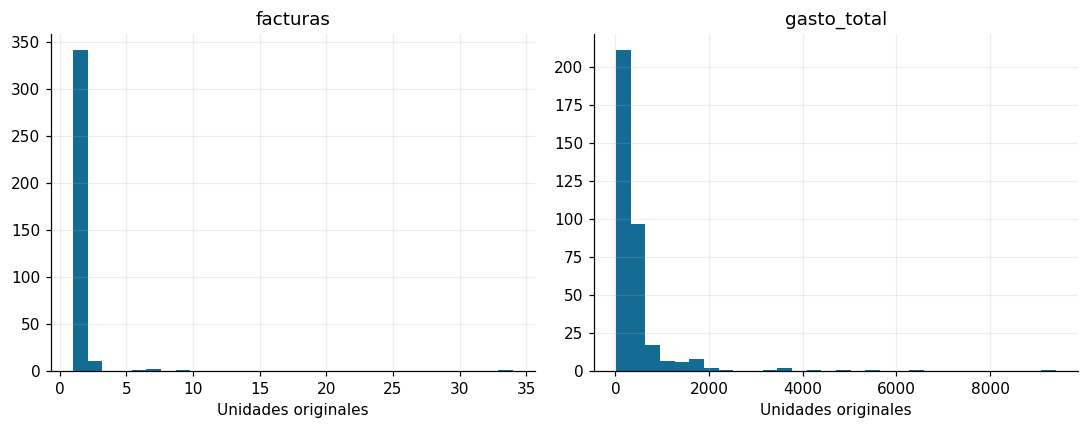

In [4]:
clientes = ventas.groupby("CustomerID", as_index=False).agg(
    facturas=("InvoiceNo", "nunique"), gasto_total=("monto_linea", "sum"),
    lineas=("InvoiceNo", "size"))
variables = ["facturas", "gasto_total"]
assert clientes[variables].gt(0).all().all()
display(clientes.head())
display(clientes[variables].describe().round(2))
print("Clientes con compras válidas:", len(clientes))
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for eje, variable in zip(ejes, variables):
    eje.hist(clientes[variable], bins=30); eje.set(title=variable, xlabel="Unidades originales")
guardar_figura("U4_2_variables_originales")

## 4. Logaritmo y dos escalados
`log1p` reduce asimetría. Min-Max coloca el mínimo y máximo observados en 0 y 1;
StandardScaler centra y divide entre la desviación estándar. Ambos dependen de los datos
observados. Se muestra la comparación y se fija la estandarización después de log1p.

,variable,min_minmax,max_minmax,media_estandar,desv_estandar
0,facturas,0.0,1.0,-0.0,1.0
1,gasto_total,0.0,1.0,0.0,1.0


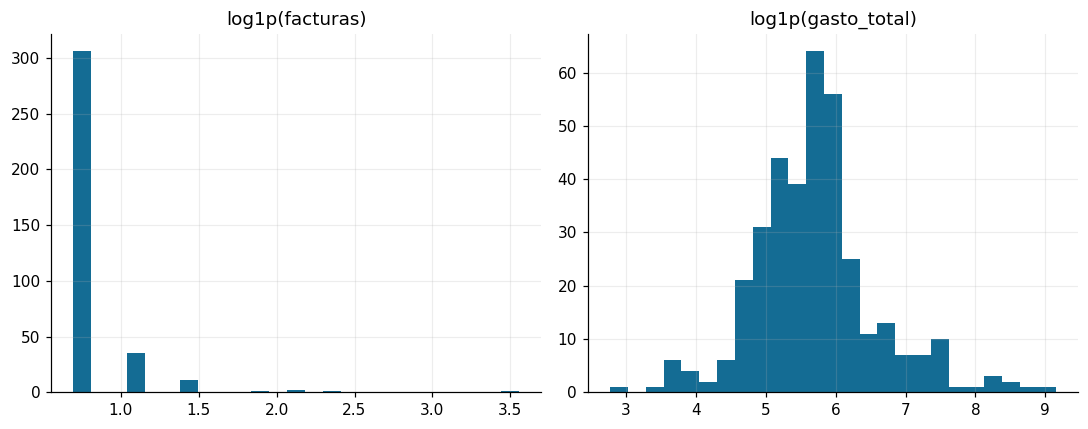

In [5]:
log_variables = np.log1p(clientes[variables])
minmax = MinMaxScaler().fit_transform(log_variables)
escalador = StandardScaler()
X = escalador.fit_transform(log_variables)
display(pd.DataFrame({"variable": variables, "min_minmax": minmax.min(axis=0),
                      "max_minmax": minmax.max(axis=0), "media_estandar": X.mean(axis=0),
                      "desv_estandar": X.std(axis=0)}).round(4))
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for eje, variable in zip(ejes, variables):
    eje.hist(log_variables[variable], bins=25); eje.set(title=f"log1p({variable})")
guardar_figura("U4_2_transformacion")

## 5. Elegir k y ajustar
Se comparan 2 a 8 grupos con la misma semilla y 20 inicializaciones. La regla elegida es
máxima silueta, complementada con inercia y perfiles. Se usan todos los clientes del recorte;
es una segmentación descriptiva y no una evaluación de predicciones futuras.

,k,inercia,silueta
0,2,413.5670,0.6805
1,3,279.5543,0.4441
2,4,181.5703,0.5045
3,5,139.1660,0.5123
4,6,103.9639,0.5381
5,7,79.3138,0.5403
6,8,56.7964,0.5618


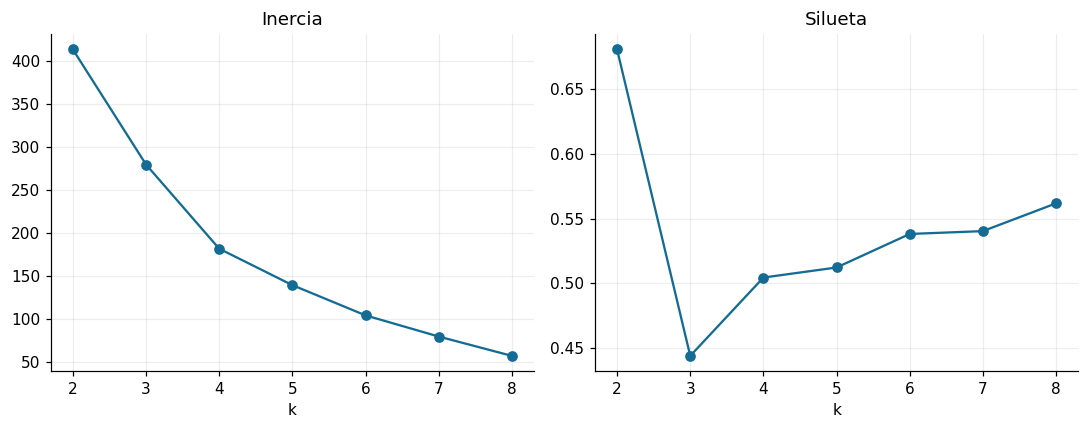

In [6]:
filas = []
for k in range(2, 9):
    candidato = KMeans(n_clusters=k, n_init=20, random_state=82005)
    etiquetas = candidato.fit_predict(X)
    filas.append({"k": k, "inercia": candidato.inertia_, "silueta": silhouette_score(X, etiquetas)})
evaluacion = pd.DataFrame(filas)
k_elegido = int(evaluacion.loc[evaluacion.silueta.idxmax(), "k"])
display(evaluacion.round(4))
modelo = KMeans(n_clusters=k_elegido, n_init=20, random_state=82005)
clientes["grupo"] = modelo.fit_predict(X)
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
ejes[0].plot(evaluacion.k, evaluacion.inercia, "o-"); ejes[0].set(title="Inercia", xlabel="k")
ejes[1].plot(evaluacion.k, evaluacion.silueta, "o-"); ejes[1].set(title="Silueta", xlabel="k")
guardar_figura("U4_2_eleccion_k")

## 6. Describir perfiles en unidades originales
Los números de grupo son etiquetas sin orden. Se interpretan con el número de clientes,
la mediana de facturas y la de gasto de cada grupo; las medianas son menos sensibles a extremos.

,clientes,facturas_mediana,gasto_mediano,facturas_promedio,gasto_promedio,porcentaje_clientes
grupo,,,,,,
0,331,1.0,277.45,1.08,337.67,92.72
1,26,3.0,1543.51,4.46,2355.77,7.28


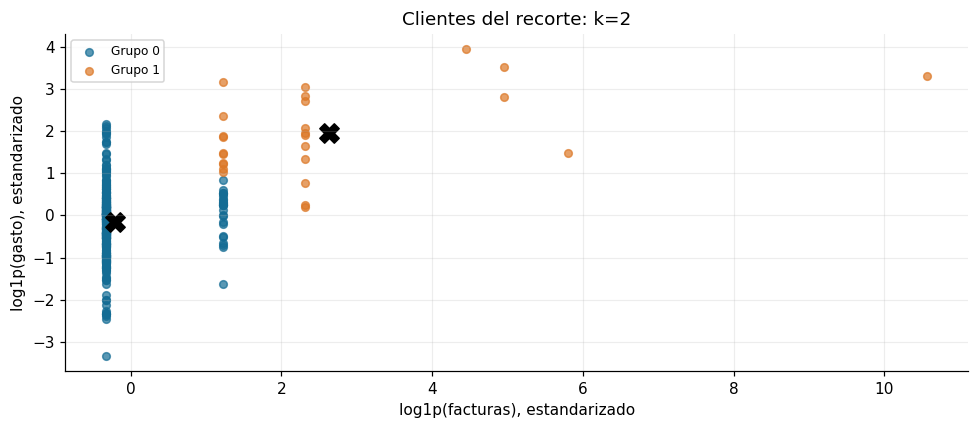

CSV guardado: U3_1_modelos_ml/data/processed/retail_clientes_segmentados.csv (357 filas)
CSV guardado: U3_1_modelos_ml/data/processed/retail_perfiles_clientes.csv (2 filas)
CSV guardado: U3_1_modelos_ml/data/processed/retail_clientes_eleccion_k.csv (7 filas)
CSV guardado: U3_1_modelos_ml/data/processed/retail_auditoria_clientes.csv (5 filas)


**Grupo 0:** 331 clientes (92.7%). Medianas: 1 facturas y 277.45 unidades monetarias.

**Grupo 1:** 26 clientes (7.3%). Medianas: 3 facturas y 1,543.51 unidades monetarias.

In [7]:
perfiles = clientes.groupby("grupo").agg(clientes=("CustomerID", "size"),
    facturas_mediana=("facturas", "median"), gasto_mediano=("gasto_total", "median"),
    facturas_promedio=("facturas", "mean"), gasto_promedio=("gasto_total", "mean"))
perfiles["porcentaje_clientes"] = 100 * perfiles.clientes / len(clientes)
display(perfiles.round(2))
for grupo in perfiles.index:
    mascara = clientes.grupo.eq(grupo)
    plt.scatter(X[mascara, 0], X[mascara, 1], label=f"Grupo {grupo}", alpha=.7, s=25)
plt.scatter(modelo.cluster_centers_[:, 0], modelo.cluster_centers_[:, 1], color="black", marker="X", s=160)
plt.xlabel("log1p(facturas), estandarizado"); plt.ylabel("log1p(gasto), estandarizado")
plt.title(f"Clientes del recorte: k={k_elegido}"); plt.legend(fontsize=8)
guardar_figura("U4_2_clientes_segmentos")
guardar_tabla(clientes, "retail_clientes_segmentados.csv")
guardar_tabla(perfiles.reset_index(), "retail_perfiles_clientes.csv")
guardar_tabla(evaluacion, "retail_clientes_eleccion_k.csv")
guardar_tabla(pd.DataFrame(auditoria), "retail_auditoria_clientes.csv")
for grupo, fila in perfiles.iterrows():
    display(Markdown(f"**Grupo {grupo}:** {int(fila.clientes)} clientes ({fila.porcentaje_clientes:.1f}%). "
        f"Medianas: {fila.facturas_mediana:g} facturas y {fila.gasto_mediano:,.2f} unidades monetarias."))

## 7. Respuestas
1. **¿Por qué excluir el identificador de X?** Una numeración arbitraria no mide cercanía comercial.
2. **¿Qué sesgo introduce exigir cliente?** Excluye compras anónimas; los perfiles no representan todas las ventas.
3. **¿Por qué agregar primero?** Para que una fila represente un cliente, en vez de cada producto comprado.
4. **¿Min-Max y estandarización son iguales?** No: usan extremos frente a media y desviación; modifican distancias.
5. **¿Cómo se eligió k?** Con la tabla de silueta y la curva de inercia, con una regla reproducible.
6. **¿Qué distingue grupos?** Sus medianas de frecuencia y gasto, calculadas arriba; la etiqueta no indica valor.
7. **¿Qué información se pierde?** Productos, países, orden temporal, devoluciones y composición de facturas.
La ventana de pocos días no permite afirmar lealtad, abandono, estacionalidad ni valor anual del cliente.
[K-Means y sus supuestos](https://scikit-learn.org/stable/modules/clustering.html#k-means).